# 12 · T1_Speech vs T2_Text on the same ids

How much does going through speech cost, and does the loss follow WER?
Outputs: headline table, BERTScore by WER bin with a plot, examples.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared").is_dir())
sys.path[:0] = [str(ROOT / "shared"), str(ROOT / "t1_speech")]

import json

from data import RESULTS_DIR, asr_path, load_jsonl, preds_path
from metrics import wer
from speech import ASR_SHORT, join_t1_t2, missed_names, wer_bin_table

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)

In [2]:
SPLIT = "dev"
ASR_MODEL = "whisper-large-v3-turbo"
VQA_MODEL, PROMPT_ID = "Qwen3-VL-4B-Instruct", "gold_style_v1"

ASR_FILE = asr_path(SPLIT, ASR_MODEL)
SPEECH = preds_path("t1_speech_cascade", SPLIT, f"{ASR_SHORT[ASR_MODEL]}+{VQA_MODEL}", PROMPT_ID)
TEXT = preds_path("t2_text", SPLIT, VQA_MODEL, PROMPT_ID)
TAG = f"{SPLIT}_{ASR_SHORT[ASR_MODEL]}+{VQA_MODEL}_{PROMPT_ID}"

n_speech, n_text = (len(load_jsonl(p)) for p in (SPEECH, TEXT))
df = join_t1_t2(ASR_FILE, SPEECH, TEXT, SPLIT)
assert len(df) == n_speech == n_text, f"speech {n_speech}, text {n_text}, common {len(df)}"
print(len(df), "common ids")

200 common ids


## 1. Headline

In [3]:
head = {
    "split": SPLIT, "n": len(df), "n_speech": n_speech, "n_text": n_text,
    "vqa": VQA_MODEL, "prompt_id": PROMPT_ID, "asr": ASR_MODEL,
    "wer_corpus": round(wer(df["transcript"].tolist(), df["question"].tolist()), 4),
    "f1_t2_text": round(df["f1_text"].mean(), 4),
    "f1_t1_speech_cascade": round(df["f1_speech"].mean(), 4),
    "delta": round(df["delta"].mean(), 4),
    "share_speech_worse_by_0.02": round((df["delta"] < -0.02).mean(), 4),
}
with open(RESULTS_DIR / f"t1_vs_t2_{TAG}.json", "w") as f:
    json.dump(head, f, indent=2)
pd.Series(head)

split                                            dev
n                                                200
n_speech                                         200
n_text                                           200
vqa                             Qwen3-VL-4B-Instruct
prompt_id                              gold_style_v1
asr                           whisper-large-v3-turbo
wer_corpus                                    0.0092
f1_t2_text                                    0.7914
f1_t1_speech_cascade                          0.7912
delta                                        -0.0002
share_speech_worse_by_0.02                     0.045
dtype: object

## 2. BERTScore by WER bin

In [4]:
bins = wer_bin_table(df)
bins.to_json(RESULTS_DIR / f"t1_vs_t2_wer_bins_{TAG}.json", indent=2)
bins

,n,f1_text,f1_speech,delta,share
wer_bin,,,,,
0,176,0.7911,0.7916,0.0004,0.880
"(0, .10]",19,0.7942,0.7884,-0.0058,0.095
"(.10, .25]",5,0.7909,0.7901,-0.0008,0.025


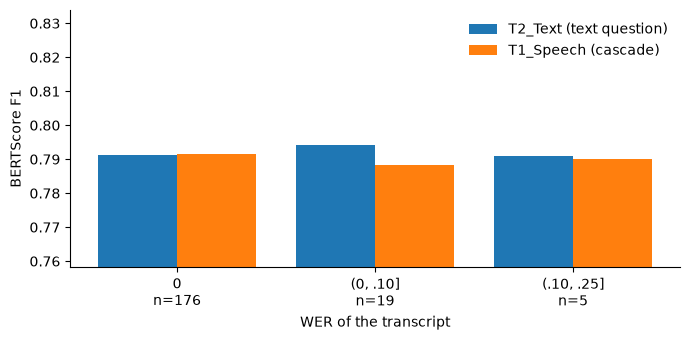

In [5]:
x = range(len(bins))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([i - 0.2 for i in x], bins["f1_text"], width=0.4, label="T2_Text (text question)")
ax.bar([i + 0.2 for i in x], bins["f1_speech"], width=0.4, label="T1_Speech (cascade)")
ax.set_xticks(list(x), [f"{b}\nn={n}" for b, n in zip(bins.index, bins["n"])])
lo = min(bins["f1_text"].min(), bins["f1_speech"].min())
ax.set_ylim(lo - 0.03, None)
ax.set_xlabel("WER of the transcript"); ax.set_ylabel("BERTScore F1")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / f"t1_vs_t2_wer_bins_{TAG}.png", dpi=200)

In [6]:
print("Spearman(WER, delta) =", round(df["wer"].corr(df["delta"], method="spearman"), 3))

Spearman(WER, delta) = -0.03


## 3. Examples

In [7]:
cols = ["wer", "delta", "question", "transcript", "answer", "pred_text", "pred_speech"]
print("ASR error -> answer broke")
df[df["wer"] > 0].sort_values("delta").head(5)[cols]

ASR error -> answer broke


,wer,delta,question,transcript,answer,pred_text,pred_speech
134,0.0500,-0.058492,"What is the purpose of the van shown in the image, and why is there luggage tied to its roof?","What is the purpose of the van shown in the image, and why is their luggage tied to its roof?","The van is used for transportation, likely public or shared transport. The luggage tied to its roof indicates that i...","The van appears to be a local transport vehicle, likely for passengers or goods, with luggage tied to its roof for c...","The van likely serves as a transport vehicle for goods or people in a Middle Eastern urban setting, with luggage tie..."
166,0.0769,-0.043642,What architectural features can be observed in this alleyway leading to the mosque?,What architectural features can be observed in this alleyway leading to the moth?,"The alleyway has whitewashed walls, a narrow pathway, and leads to a mosque with a minaret and dome. Palm trees are ...","The alleyway leads to the mosque, featuring whitewashed walls, arched doorways, and a thatched roof, typical of trad...","The alleyway leads to the Ksar of Aït Benhaddou, featuring whitewashed walls, arched doorways, and a central tower, ..."
156,0.0769,-0.038852,What is the significance of 'The Pointe' in the context of the image?,What is the significance of the point in the context of the image?,"'The Pointe' is a waterfront destination in Dubai known for its scenic views, entertainment options, and proximity t...","The Pointe is a beachfront promenade in Dubai, offering scenic views of the Atlantis hotel and vibrant evening ambia...","The point in the image is a beachfront promenade, likely The Point, offering scenic views of the Atlantis hotel and ..."
148,0.0833,-0.035453,What is the cultural significance of the pyramids shown in the image?,What is the cultural significance of the pyramid shown in the image?,"The pyramids in the image are Nubian pyramids, which were built as tombs for the kings and queens of the ancient Kin...","The pyramids shown are Meroe’s ancient Nubian pyramids, symbolizing Nubian kingship and spiritual beliefs, reflectin...","The pyramids shown are Meroe’s ancient Nubian pyramids, symbolizing Nubian kingship and spiritual beliefs, reflectin..."
19,0.0833,-0.022631,What architectural elements in the image suggest the town’s historical significance?,What architectural elements in the image suggest the town's historical significance?,"The image features fortified walls, whitewashed buildings, and a minaret, all of which are indicative of a historic ...","The town’s fortified walls and mosque tower suggest historical significance, reflecting medieval defense and Islamic...","The town's white-washed buildings and stone fortifications suggest historical significance, likely dating to medieva..."


In [8]:
print("ASR error, answer survived")
df[(df["wer"] > 0.1) & (df["delta"] > -0.01)].sort_values("wer", ascending=False).head(5)[cols]

ASR error, answer survived


,wer,delta,question,transcript,answer,pred_text,pred_speech
142,0.1818,-0.006194,What national symbol is displayed on the mousepad in the image?,What national symbol is displayed on the mouse pad in the image?,"The mousepad displays the flag of Oman, which is a national symbol representing the country.","The mousepad displays Oman’s national flag, featuring green, red, and white stripes with a white sword emblem, symbo...","The mouse pad displays Oman’s national flag, featuring green, red, and white stripes with a white sword emblem, symb..."
2,0.1250,0.027204,What is the significance of the stone hand sculpture and the ancient ruins in the image?,What is the significance of the Stonehand sculpture and the ancient ruins in the image?,"The stone hand sculpture and the ancient ruins are part of the Amman Citadel in Jordan, which holds great historical...","The stone hand sculpture at the ancient ruins likely symbolizes human connection to history, contrasting with the en...","The Stonehand sculpture, placed before ancient ruins, symbolizes resilience and historical continuity. It’s a modern..."
179,0.1111,0.002369,What architectural features distinguish the mosque in the image?,What architectural features distinguish the mask in the image?,"The mosque has beige-colored walls, a tall minaret, intricate geometric designs on the windows, and a large open cou...","The mosque features a tall minaret and crenellated walls with geometric lattice windows, reflecting traditional Isla...","The mosque's architecture features terracotta walls, geometric lattice windows, and a tall minaret with crenellation..."
132,0.1053,-0.008598,What does the text 'Royal Force' in the upper-right corner suggest about the damaged aircraft in the image?,What does the text Royal For is in the upper right corner suggest about the damaged aircraft in the image?,"The text 'Royal Force' suggests that the damaged aircraft likely belonged to a military or air force organization, p...","The text 'Royal Force' suggests the aircraft belongs to the Royal Navy's air arm, likely involved in naval operation...","The text ""Royal Force"" in the upper right corner suggests the aircraft belongs to the Royal Air Force, likely indica..."


In [9]:
df["missed"] = [missed_names(q, t) for q, t in zip(df["question"], df["transcript"])]
m = df["missed"].map(len) > 0
print(f"lost a name/place/dish: {m.mean():.1%} of questions; "
      f"mean delta {df.loc[m, 'delta'].mean():.4f} vs {df.loc[~m, 'delta'].mean():.4f} without")
df[m].sort_values("delta").head(5)[["missed"] + cols]

lost a name/place/dish: 1.5% of questions; mean delta -0.0196 vs 0.0001 without


,missed,wer,delta,question,transcript,answer,pred_text,pred_speech
156,[Pointe],0.0769,-0.038852,What is the significance of 'The Pointe' in the context of the image?,What is the significance of the point in the context of the image?,"'The Pointe' is a waterfront destination in Dubai known for its scenic views, entertainment options, and proximity t...","The Pointe is a beachfront promenade in Dubai, offering scenic views of the Atlantis hotel and vibrant evening ambia...","The point in the image is a beachfront promenade, likely The Point, offering scenic views of the Atlantis hotel and ..."
37,[ESSAOUIRA],0.0714,-0.011376,"What does the text 'ESSAOUIRA' on the boat signify, and where is it located?","What does the text Esawaira on the boat signify, and where is it located?","The text 'ESSAOUIRA' refers to a coastal city in Morocco, known for its historic architecture and maritime culture. ...","The text 'ESSAOUIRA' on the boat signifies the city's name, located in Morocco. It reflects local maritime heritage ...","The boat's ""Essaouira"" text signifies the Moroccan coastal city, known for its historic medina and fishing heritage,..."
132,[Force],0.1053,-0.008598,What does the text 'Royal Force' in the upper-right corner suggest about the damaged aircraft in the image?,What does the text Royal For is in the upper right corner suggest about the damaged aircraft in the image?,"The text 'Royal Force' suggests that the damaged aircraft likely belonged to a military or air force organization, p...","The text 'Royal Force' suggests the aircraft belongs to the Royal Navy's air arm, likely involved in naval operation...","The text ""Royal Force"" in the upper right corner suggests the aircraft belongs to the Royal Air Force, likely indica..."


## 4. By category
The released EN data (train, dev, devtest) has no `category` / `country`, and devtest has no `answer`.
Kept for the test-phase gold or a future labelled release; prints a note otherwise.

In [10]:
if df["category"].notna().any():
    from IPython.display import display
    display(df.groupby("category")[["f1_text", "f1_speech", "delta", "wer"]].mean().round(4)
              .sort_values("delta"))
else:
    print("no category in", SPLIT)

no category in dev
